# 기본 01 · 이미지 읽기와 BGR 채널

`01_read.py`의 B01 구현과 실제 실행 결과를 확인합니다.

흐름: 입력 경로 준비 → `cv2.imread` → shape·dtype·범위·픽셀 확인 → PNG 저장.

`imread`의 기본 컬러 순서는 BGR입니다. `shape`는 (높이, 너비, 채널)이고 `uint8`은 채널 값을 0~255의 정수로 표현합니다. `imwrite` 반환값은 저장 성공 여부입니다. 이 실습은 원본 옆에 `p01_copy.png`를 저장합니다.

이 노트북은 실제 코드를 실행하고 결과를 표시합니다. 입력은 보존하고 실습 코드의 출력 파일은 다시 생성합니다. 프로젝트 `.venv` 등 `opencv-python`, `numpy`, `matplotlib`, `pandas`, `IPython`이 설치된 커널에서 위에서부터 실행하세요.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image

# 노트북 폴더 또는 프로젝트 내부에서 실행할 수 있도록 루트를 찾습니다.
notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/01_기본필수/01_read.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/01_기본필수"


## 1. 실습 코드 실행

현재 Python 파일의 코드를 사용합니다. 노트북에는 `__file__`이 없으므로 원본의 경로 준비 부분만 `exercise`로 바꿨습니다. TODO 구현과 출력 계산은 그대로입니다.

In [2]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

# 색상 이미지: 한 픽셀의 값 순서는 B, G, R입니다.
# >>> TODO B01
# scene.png를 cv2.imread로 읽어 image에 저장하세요. flags를 생략하면 BGR 컬러로 읽습니다.
image = cv2.imread('scene.png')
# <<< TODO B01
print("shape:", image.shape)
print("dtype:", image.dtype)
print("min/max:", int(image.min()), int(image.max()))
print("빨강 패치의 BGR:", image[30, 30].tolist())
saved = cv2.imwrite("p01_copy.png", image)
print("PNG 저장:", saved)


shape: (240, 320, 3)
dtype: uint8
min/max: 0 255
빨강 패치의 BGR: [0, 0, 255]
PNG 저장: True


## 2. 실제 결과 확인과 검증

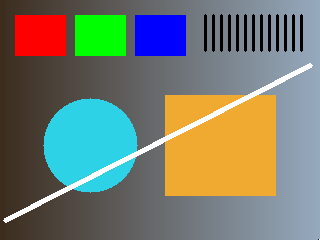

검증: 입력 크기·자료형·빨강 패치·PNG 재읽기 픽셀 일치


In [3]:
display(Image(filename=str(exercise / "p01_copy.png")))
copy = cv2.imread("p01_copy.png")
assert image.shape == (240, 320, 3)
assert image.dtype == np.uint8
assert image[30, 30].tolist() == [0, 0, 255]
assert saved and np.array_equal(image, copy)
print("검증: 입력 크기·자료형·빨강 패치·PNG 재읽기 픽셀 일치")

## 3. 결과 해석

빨강 패치의 `[0, 0, 255]`는 B=0, G=0, R=255를 뜻합니다. 표시된 이미지는 저장한 PNG이며, 재읽기한 배열을 원본과 비교해 픽셀 보존 여부를 확인했습니다.

출력 파일은 실행 중 생성되며, 이 노트북에는 실행 출력과 이미지가 포함되어 있습니다.

In [4]:
os.chdir(notebook_start)  # 노트북 실행 전 작업 폴더로 돌아갑니다.